In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DATA = Path("../data")

# Load merged dataset (A8 subset)
df = pd.read_csv(DATA / "merged_school_dataset.csv")

numeric_features = [
    "fsm_pct_2024", "imd_score", "income_score", "employment_score",
    "health_score", "crime_score", "barriers_score", "living_env_score",
    "idaci_score", "adult_skills_score", "geo_barriers_score",
    "wider_barriers_score", "indoors_score", "outdoors_score",
    "p8_2023", "a8_2024",
]

# A8 subset: schools with a8_2025 available
df_a8 = df.loc[df["a8_2025"].notna()].copy()
X_raw = df_a8[numeric_features]
y_raw = df_a8["a8_2025"].values

# 70/15/15 split
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X_raw, y_raw, test_size=0.30, random_state=SEED
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=SEED
)

# Preprocess — median impute + standardise, fitted on train only
imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()

X_train = scaler.fit_transform(imputer.fit_transform(X_train_raw))
X_val   = scaler.transform(imputer.transform(X_val_raw))
X_test  = scaler.transform(imputer.transform(X_test_raw))

# Also standardise the target — helps neural networks train stably
y_mean = y_train.mean()
y_std  = y_train.std()
y_train_scaled = (y_train - y_mean) / y_std
y_val_scaled   = (y_val   - y_mean) / y_std
y_test_scaled  = (y_test  - y_mean) / y_std

# Convert to tensors
X_train_t = torch.FloatTensor(X_train)
X_val_t   = torch.FloatTensor(X_val)
X_test_t  = torch.FloatTensor(X_test)
y_train_t = torch.FloatTensor(y_train_scaled).unsqueeze(1)
y_val_t   = torch.FloatTensor(y_val_scaled).unsqueeze(1)
y_test_t  = torch.FloatTensor(y_test_scaled).unsqueeze(1)

print(f"Train: {X_train_t.shape} | Val: {X_val_t.shape} | Test: {X_test_t.shape}")
print(f"Target (a8_2025) — train mean {y_mean:.2f}, std {y_std:.2f}")

Train: torch.Size([2250, 16]) | Val: torch.Size([482, 16]) | Test: torch.Size([483, 16])
Target (a8_2025) — train mean 47.03, std 9.40


In [2]:
class A8ANN(nn.Module):
    """
    Feed-forward ANN for A8 regression.
    Architecture: 16 -> 64 -> 32 -> 1 (single continuous output).
    """
    def __init__(self, n_features=16, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
model = A8ANN(n_features=16, dropout=0.3)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal trainable parameters: {n_params:,}")

A8ANN(
  (net): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total trainable parameters: 3,201


In [3]:
# Re-seed and rebuild model so re-runs are reproducible
torch.manual_seed(SEED)
model = A8ANN(n_features=16, dropout=0.3)

EPOCHS   = 300
LR       = 0.001
PATIENCE = 40

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

train_losses, val_losses, val_rmses = [], [], []
best_val_rmse = float("inf")
best_epoch = 0
best_state = None
epochs_no_improve = 0

for epoch in range(EPOCHS):
    # Train
    model.train()
    optimizer.zero_grad()
    pred = model(X_train_t)
    loss = criterion(pred, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    # Evaluate on val (in original units)
    model.eval()
    with torch.no_grad():
        val_pred_scaled = model(X_val_t).numpy().ravel()
        val_pred = val_pred_scaled * y_std + y_mean       # de-standardise
        val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
        val_loss = criterion(model(X_val_t), y_val_t).item()

    val_losses.append(val_loss)
    val_rmses.append(val_rmse)

    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_epoch = epoch
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    if epoch % 10 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch {epoch:>3}: train_loss={loss.item():.4f}  val_loss={val_loss:.4f}  val_RMSE={val_rmse:.2f}")

    if epochs_no_improve >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

model.load_state_dict(best_state)
print(f"\nBest model: epoch {best_epoch}, val RMSE = {best_val_rmse:.2f}")

Epoch   0: train_loss=1.0800  val_loss=0.8652  val_RMSE=8.75
Epoch  10: train_loss=0.8578  val_loss=0.6734  val_RMSE=7.72
Epoch  20: train_loss=0.6241  val_loss=0.4799  val_RMSE=6.51
Epoch  30: train_loss=0.4314  val_loss=0.2996  val_RMSE=5.15
Epoch  40: train_loss=0.3233  val_loss=0.1893  val_RMSE=4.09
Epoch  50: train_loss=0.2526  val_loss=0.1365  val_RMSE=3.47
Epoch  60: train_loss=0.2261  val_loss=0.1204  val_RMSE=3.26
Epoch  70: train_loss=0.2061  val_loss=0.1136  val_RMSE=3.17
Epoch  80: train_loss=0.1937  val_loss=0.1079  val_RMSE=3.09
Epoch  90: train_loss=0.1886  val_loss=0.1042  val_RMSE=3.04
Epoch 100: train_loss=0.1776  val_loss=0.1011  val_RMSE=2.99
Epoch 110: train_loss=0.1719  val_loss=0.0986  val_RMSE=2.95
Epoch 120: train_loss=0.1668  val_loss=0.0975  val_RMSE=2.94
Epoch 130: train_loss=0.1687  val_loss=0.0952  val_RMSE=2.90
Epoch 140: train_loss=0.1651  val_loss=0.0933  val_RMSE=2.87
Epoch 150: train_loss=0.1442  val_loss=0.0926  val_RMSE=2.86
Epoch 160: train_loss=0.

In [4]:
model.eval()
with torch.no_grad():
    test_pred_scaled = model(X_test_t).numpy().ravel()

# De-standardise back to A8 units
test_pred = test_pred_scaled * y_std + y_mean

# Metrics in original units
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_mae  = mean_absolute_error(y_test, test_pred)
test_r2   = r2_score(y_test, test_pred)

print(f"═══ A8 ANN Test-set performance ═══")
print(f"R²:    {test_r2:.3f}")
print(f"RMSE:  {test_rmse:.2f}  (target SD ≈ {y_std:.2f})")
print(f"MAE:   {test_mae:.2f}")

# Save model
import os
os.makedirs("../models", exist_ok=True)
torch.save(best_state, "../models/a8_ann.pt")
print("\nSaved best model to ../models/a8_ann.pt")

═══ A8 ANN Test-set performance ═══
R²:    0.901
RMSE:  3.03  (target SD ≈ 9.40)
MAE:   2.33

Saved best model to ../models/a8_ann.pt


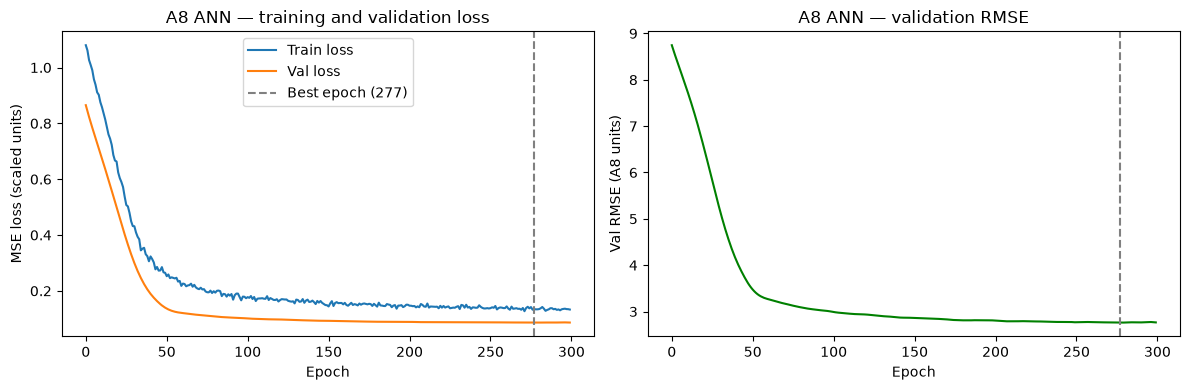

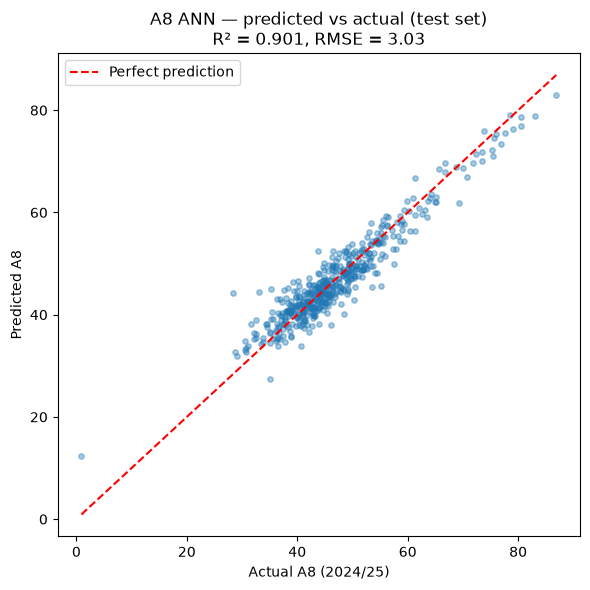


A8 model comparison:
                                Model    R²  RMSE
Random Forest (with p8_2023, a8_2024) 0.890  3.02
          ANN (with p8_2023, a8_2024) 0.901  3.03


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_losses, label="Train loss")
axes[0].plot(val_losses, label="Val loss")
axes[0].axvline(best_epoch, color="grey", linestyle="--", label=f"Best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss (scaled units)")
axes[0].set_title("A8 ANN — training and validation loss")
axes[0].legend()

axes[1].plot(val_rmses, color="green")
axes[1].axvline(best_epoch, color="grey", linestyle="--")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Val RMSE (A8 units)")
axes[1].set_title("A8 ANN — validation RMSE")
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_a8_ann_training.png", dpi=150, bbox_inches="tight")
plt.show()

# Predicted vs actual scatter
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_pred, alpha=0.4, s=15)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
        "r--", label="Perfect prediction")
ax.set_xlabel("Actual A8 (2024/25)")
ax.set_ylabel("Predicted A8")
ax.set_title(f"A8 ANN — predicted vs actual (test set)\nR² = {test_r2:.3f}, RMSE = {test_rmse:.2f}")
ax.legend()
plt.tight_layout()
plt.savefig("../SRC/EDA/fig_a8_ann_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

# Comparison with the RF baseline you already ran
comparison = pd.DataFrame({
    "Model":     ["Random Forest (with p8_2023, a8_2024)",
                  "ANN (with p8_2023, a8_2024)"],
    "R²":        [0.890, round(test_r2, 3)],
    "RMSE":      [3.02,  round(test_rmse, 2)],
})
print("\nA8 model comparison:")
print(comparison.to_string(index=False))

In [6]:
# Permutation importance to see which features actually drive predictions
from sklearn.inspection import permutation_importance

# ANN permutation importance (approximation using numpy)
import copy
baseline_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

importances = {}
for i, feat in enumerate(numeric_features):
    X_test_shuffled = X_test.copy()
    rng = np.random.default_rng(42)
    rng.shuffle(X_test_shuffled[:, i])
    with torch.no_grad():
        pred_shuffled = model(torch.FloatTensor(X_test_shuffled)).numpy().ravel()
        pred_shuffled = pred_shuffled * y_std + y_mean
    rmse_shuffled = np.sqrt(mean_squared_error(y_test, pred_shuffled))
    importances[feat] = rmse_shuffled - baseline_rmse

importance_df = pd.DataFrame({
    "feature": list(importances.keys()),
    "rmse_increase_when_shuffled": list(importances.values()),
}).sort_values("rmse_increase_when_shuffled", ascending=False)

print("Permutation importance (higher = more important to predictions):")
print(importance_df.to_string(index=False))

Permutation importance (higher = more important to predictions):
             feature  rmse_increase_when_shuffled
             a8_2024                     7.772699
             p8_2023                     0.636448
         idaci_score                     0.186031
  adult_skills_score                     0.139660
        fsm_pct_2024                     0.134416
        income_score                     0.120996
wider_barriers_score                     0.098778
    living_env_score                     0.097438
  geo_barriers_score                     0.096755
       indoors_score                     0.086366
    employment_score                     0.068396
      barriers_score                     0.061222
           imd_score                     0.057521
      outdoors_score                     0.040926
        health_score                     0.024296
         crime_score                    -0.008953


In [7]:
# Ablation: A8 ANN without prior-year performance
socio_features = [f for f in numeric_features if f not in ("p8_2023", "a8_2024")]

X_train_socio_raw = X_train_raw[socio_features]
X_test_socio_raw  = X_test_raw[socio_features]

imputer_s = SimpleImputer(strategy="median")
scaler_s  = StandardScaler()
X_train_s = scaler_s.fit_transform(imputer_s.fit_transform(X_train_socio_raw))
X_test_s  = scaler_s.transform(imputer_s.transform(X_test_socio_raw))

X_train_st = torch.FloatTensor(X_train_s)
X_test_st  = torch.FloatTensor(X_test_s)

torch.manual_seed(SEED)
model_socio = A8ANN(n_features=len(socio_features), dropout=0.3)
optimizer_s = torch.optim.Adam(model_socio.parameters(), lr=0.001)
criterion_s = nn.MSELoss()

for epoch in range(200):
    model_socio.train()
    optimizer_s.zero_grad()
    loss = criterion_s(model_socio(X_train_st), y_train_t)
    loss.backward()
    optimizer_s.step()

model_socio.eval()
with torch.no_grad():
    pred_socio = model_socio(X_test_st).numpy().ravel() * y_std + y_mean

r2_socio_a8 = r2_score(y_test, pred_socio)
rmse_socio_a8 = np.sqrt(mean_squared_error(y_test, pred_socio))

print(f"\n═══ A8 ANN — SOCIO-ECONOMIC ONLY (ablation) ═══")
print(f"R²:    {r2_socio_a8:.3f}")
print(f"RMSE:  {rmse_socio_a8:.3f}")
print(f"\nGap vs full model (R² 0.901):")
print(f"  R² drop:  {0.901 - r2_socio_a8:.3f}  (attributable to prior-year performance)")


═══ A8 ANN — SOCIO-ECONOMIC ONLY (ablation) ═══
R²:    0.530
RMSE:  6.598

Gap vs full model (R² 0.901):
  R² drop:  0.371  (attributable to prior-year performance)
